# Logical paradoxes as dynamical systems

A lab for the [SF Cog Sci reading group](https://github.com/m9h/sf-cogsci-ingressing-minds).
Source equations: [Mar & Grim (1991)](https://pgrim.org/articles/patternandchaos.pdf).
These are original experiments, not copies of the paper's figures. See
[the mathematical guide](../docs/mathematics.md) for page references and derivations.

Run with the repository's locked Python environment. The saved outputs work without
widgets; the last cell adds controls when opened in a live notebook.

In [1]:
import math
from fractions import Fraction as Q
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display

from paradox_dynamics import simulate
from paradox_dynamics.engine import SCHEDULES
from paradox_dynamics.plotting import plot_trajectory

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

Matplotlib is building the font cache; this may take a moment.


## 1. A claim and a revision are different functions

The revision schema is `R_s(x) = 1 - abs(s(x)-x)`. Assigning `s(x)=0`
yields the Simple Liar, `1-x`. Assigning `s(x)=1-x` yields the tent map.
Our variable is a chosen semantic value, not automatically a probability.

First predict what happens to `1/4`, `1/2`, and `1` under the Simple Liar.

1/4 → ['1/4', '3/4', '1/4', '3/4', '1/4', '3/4', '1/4'] {'start': 0, 'period': 2, 'first_repeat': 2}
1/2 → ['1/2', '1/2', '1/2', '1/2', '1/2', '1/2', '1/2'] {'start': 0, 'period': 1, 'first_repeat': 1}
1 → ['1', '0', '1', '0', '1', '0', '1'] {'start': 0, 'period': 2, 'first_repeat': 2}


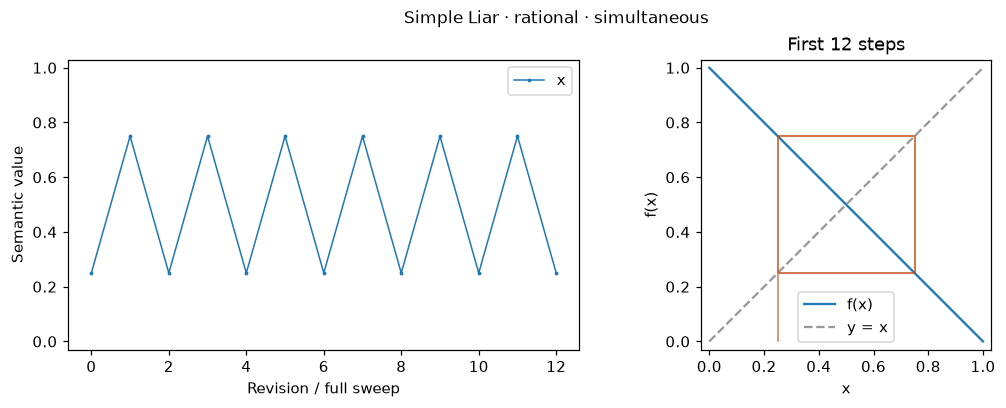

In [2]:
for start in ["1/4", "1/2", "1"]:
    run = simulate("liar", start, steps=6, precision="rational")
    print(start, "→", [str(x) for (x,) in run.states], run.diagnostics()["recurrence"])
liar = simulate("liar", "1/4", steps=12, precision="rational")
display(plot_trajectory(liar))
plt.close("all")

## 2. Same fixed point, different stability

The Half-Sayer (`k=1/2`) and Minimalist both fix `2/3`.
For the Half-Sayer, an error shrinks by a factor of `-1/2` each step;
for the Minimalist, a small error grows by `-2` until the orbit leaves that branch.
Keep the fixed point exact so that a rounded starting value does not confuse the comparison.

k-sayer exact fixed-point recurrence: {'start': 0, 'period': 1, 'first_repeat': 1}
minimalist exact fixed-point recurrence: {'start': 0, 'period': 1, 'first_repeat': 1}


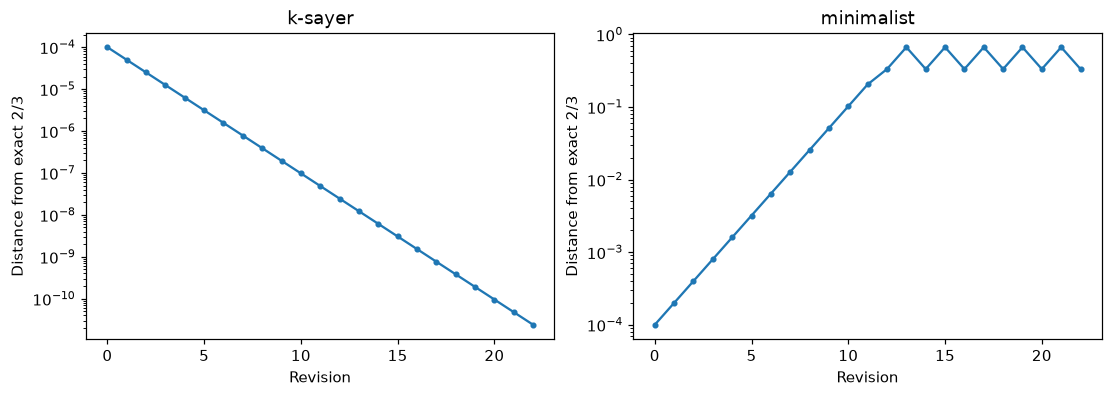

In [3]:
fixed = Q(2, 3)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), constrained_layout=True)
for ax, model in zip(axes, ["k-sayer", "minimalist"]):
    run = simulate(model, fixed + Q(1, 10000), steps=22, precision="rational")
    error = [float(abs(x - fixed)) for (x,) in run.states]
    ax.semilogy(error, ".-")
    ax.set(title=model, xlabel="Revision", ylabel="Distance from exact 2/3")
    stationary = simulate(model, fixed, steps=20, precision="rational")
    print(model, "exact fixed-point recurrence:", stationary.diagnostics()["recurrence"])
display(fig)
plt.close(fig)

## 3. A published short trajectory as a reference

Printed p. 671 compares tent-map starts `0.314` and `0.3141`.
Exact rational arithmetic reproduces its twenty revisions without decimal drift.
The automated tests compare every entry with the published table.

 n       x0=.314    x0=.3141    separation
 0       0.3140       0.3141       0.0001
 1       0.6280       0.6282       0.0002
 2       0.7440       0.7436       0.0004
 3       0.5120       0.5128       0.0008
 4       0.9760       0.9744       0.0016
 5       0.0480       0.0512       0.0032
 6       0.0960       0.1024       0.0064
 7       0.1920       0.2048       0.0128
 8       0.3840       0.4096       0.0256
 9       0.7680       0.8192       0.0512
10       0.4640       0.3616       0.1024
11       0.9280       0.7232       0.2048
12       0.1440       0.5536       0.4096
13       0.2880       0.8928       0.6048
14       0.5760       0.2144       0.3616
15       0.8480       0.4288       0.4192
16       0.3040       0.8576       0.5536
17       0.6080       0.2848       0.3232
18       0.7840       0.5696       0.2144
19       0.4320       0.8608       0.4288
20       0.8640       0.2784       0.5856


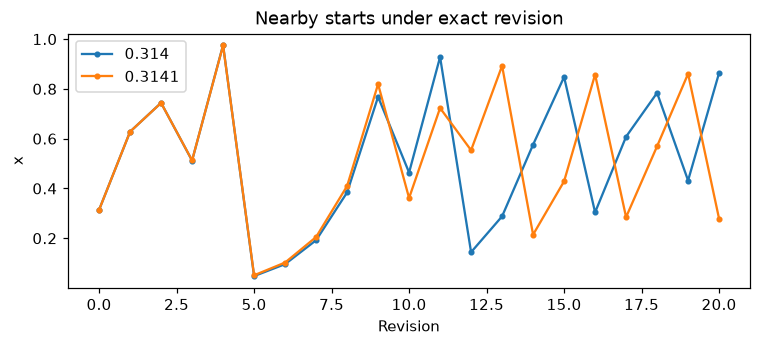

In [4]:
a = simulate("chaotic-liar", "0.314", steps=20, precision="rational")
b = simulate("chaotic-liar", "0.3141", steps=20, precision="rational")
print(" n       x0=.314    x0=.3141    separation")
for n, (u, v) in enumerate(zip(a.states, b.states)):
    print(
        f"{n:2d}       {float(u[0]):.4f}       {float(v[0]):.4f}   "
        f"    {float(abs(u[0] - v[0])):.4f}"
    )
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(a.array()[:, 0], ".-", label="0.314")
ax.plot(b.array()[:, 0], ".-", label="0.3141")
ax.set(xlabel="Revision", ylabel="x", title="Nearby starts under exact revision")
ax.legend()
display(fig)
plt.close(fig)

## 4. The computer changes the long trajectory

Now keep the requested input fixed and change its representation. Binary floats
are dyadic rationals: tent-map iteration eventually reaches zero. A non-dyadic
rational can have a different recurring orbit. Finite rational orbits still do
not describe every real initial condition.

Only plotting converts an exact trajectory to float64; the simulator retains fractions.

float32 first zero: 24 recurrence: {'start': 24, 'period': 1, 'first_repeat': 25}
float64 first zero: 55 recurrence: {'start': 55, 'period': 1, 'first_repeat': 56}
rational first zero: None recurrence: {'start': 3, 'period': 50, 'first_repeat': 53}


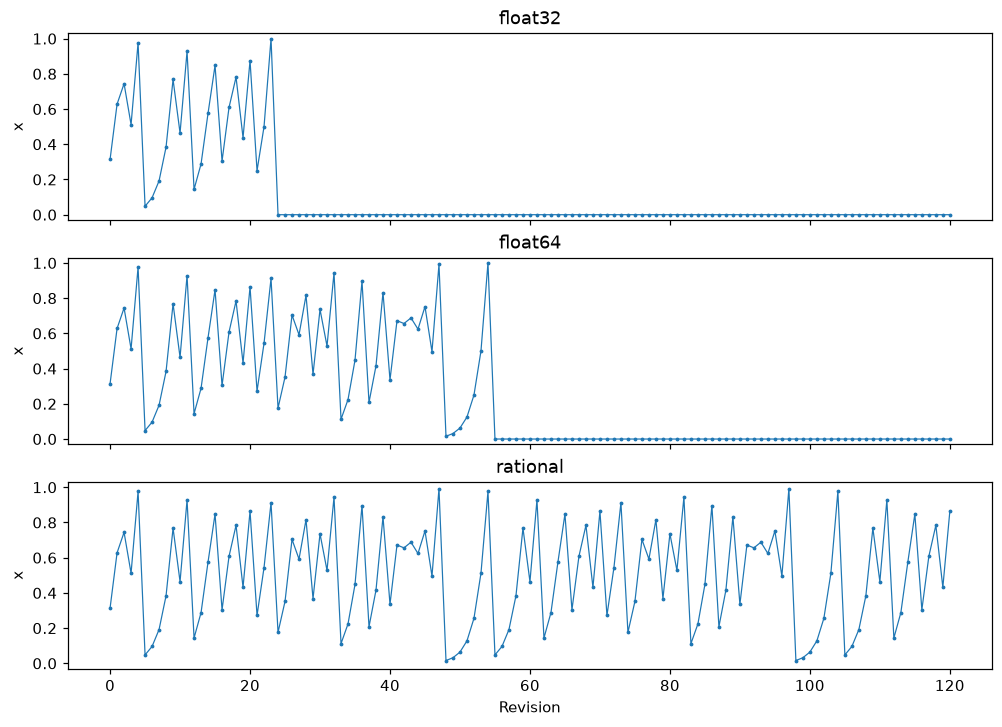

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(9, 6.5), sharex=True, constrained_layout=True)
for ax, precision in zip(axes, ["float32", "float64", "rational"]):
    run = simulate("chaotic-liar", "0.314", steps=120, precision=precision)
    first_zero = next((n for n, (x,) in enumerate(run.states) if x == 0), None)
    print(precision, "first zero:", first_zero, "recurrence:", run.diagnostics()["recurrence"])
    ax.plot(run.array()[:, 0], ".-", markersize=3, linewidth=0.8)
    ax.set(title=precision, ylabel="x", ylim=(-0.03, 1.03))
axes[-1].set_xlabel("Revision")
display(fig)
plt.close(fig)

## 5. Positive expansion does not classify an orbit as chaotic

At exactly `2/3`, the tent orbit is fixed. Its real-valued derivative is still `-2`.
The finite-time mean of `log(abs(f'(x)))` is therefore `log(2)` even on this periodic
orbit. At the tent's corner `1/2`, the ordinary derivative is undefined.

In [6]:
fixed_run = simulate("chaotic-liar", "2/3", steps=12, precision="rational")
print("Exact fixed orbit:", fixed_run.diagnostics())
print("log(2) =", math.log(2))
corner = simulate("chaotic-liar", "1/2", steps=4, precision="rational")
print("Corner status:", corner.diagnostics()["tangent_log_gain"]["status"])

Exact fixed orbit: {'recurrence': {'start': 0, 'period': 1, 'first_repeat': 1}, 'recurrence_meaning': 'Exact recurrence for this rational initial state', 'tangent_log_gain': {'value': 0.6931471805599453, 'status': 'finite', 'samples': 12, 'units': 'natural-log units per iteration', 'interpretation': 'Finite-time derivative growth of the real equation; not a test for chaos or a derivative of rounded arithmetic'}}
log(2) = 0.6931471805599453
Corner status: undefined_at_corner


## 6. Update order belongs in the model

For the Simple Dualist the component rules are `x'=1-y`, `y'=x`.
Updating both from old values gives a period-four orbit. A sequential sweep
feeds a new value into the other component and changes that orbit.
The paper's simple-pair convention is **y-then-x**.

In [7]:
for schedule in SCHEDULES:
    run = simulate("dualist", ["1/4", "1/8"], steps=8, precision="rational", schedule=schedule)
    print(schedule, ":", [tuple(map(str, row)) for row in run.states[:5]])
    print("  recurrence:", run.diagnostics()["recurrence"])

simultaneous : [('1/4', '1/8'), ('7/8', '1/4'), ('3/4', '7/8'), ('1/8', '3/4'), ('1/4', '1/8')]
  recurrence: {'start': 0, 'period': 4, 'first_repeat': 4}
x-then-y : [('1/4', '1/8'), ('7/8', '7/8'), ('1/8', '1/8'), ('7/8', '7/8'), ('1/8', '1/8')]
  recurrence: {'start': 1, 'period': 2, 'first_repeat': 3}
y-then-x : [('1/4', '1/8'), ('3/4', '1/4'), ('1/4', '3/4'), ('3/4', '1/4'), ('1/4', '3/4')]
  recurrence: {'start': 1, 'period': 2, 'first_repeat': 3}


The later Dualist pair uses `A=1-|y-x|`, `B=1-|(1-x)-y|`.
The following **new** initial pair has longer rational denominators than the short
examples in the paper. We plot 6,000 complete sweeps, with no discarded burn-in.
An orange cross marks the initial state. Dense-looking output is not a proof of an attractor.

simultaneous recurrence within this run: None


x-then-y recurrence within this run: None


y-then-x recurrence within this run: None


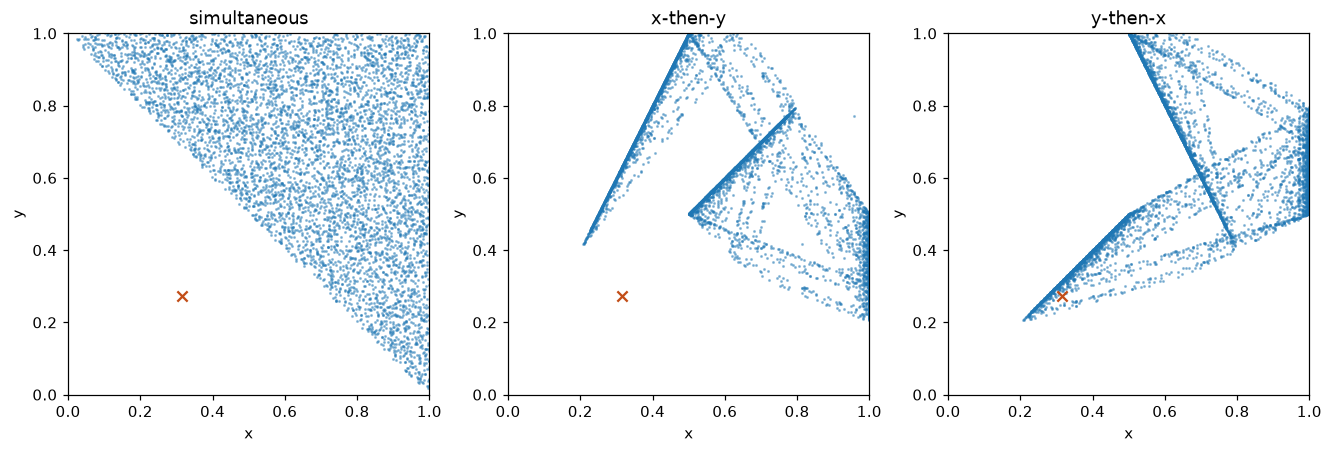

In [8]:
initial = ["0.314159265358979323846", "0.271828182845904523536"]
fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
for ax, schedule in zip(axes, SCHEDULES):
    run = simulate("dual-revision", initial, steps=6000, precision="rational", schedule=schedule)
    values = run.array()
    ax.scatter(values[1:, 0], values[1:, 1], s=1, alpha=0.4)
    ax.scatter(*values[0], c="#c24e18", marker="x", s=45)
    ax.set(title=schedule, xlabel="x", ylabel="y", aspect="equal", xlim=(0, 1), ylim=(0, 1))
    print(schedule, "recurrence within this run:", run.diagnostics()["recurrence"])
display(fig)
plt.close(fig)

Compare that with exact short-decimal inputs `(0.1, 0.9)` and the paper's
x-then-y update. A finite grid can produce a much shorter orbit. The plot and
this calculation answer different questions because the starting values differ.

In [9]:
for precision in ["rational", "float32", "float64"]:
    run = simulate(
        "dual-revision", ["0.1", "0.9"], steps=200, precision=precision, schedule="x-then-y"
    )
    print(precision, run.diagnostics()["recurrence"])

rational {'start': 21, 'period': 3, 'first_repeat': 24}
float32 None
float64 None


## 7. Check a parameter boundary before reading the picture

For the displayed Curry variation, `p=0` gives the tent map; `p=1` gives the
identity. The latter differs from the prose at the top of printed p. 675.
The implementation follows the equation, and the tests record the discrepancy.
An interior example (`p=3/4`, `x0=1/5`) reaches `17/20 ↔ 9/10`.

Interior cycle: [(Fraction(9, 10),), (Fraction(17, 20),), (Fraction(9, 10),), (Fraction(17, 20),)]
p=1: ['23/100', '23/100', '23/100', '23/100', '23/100']


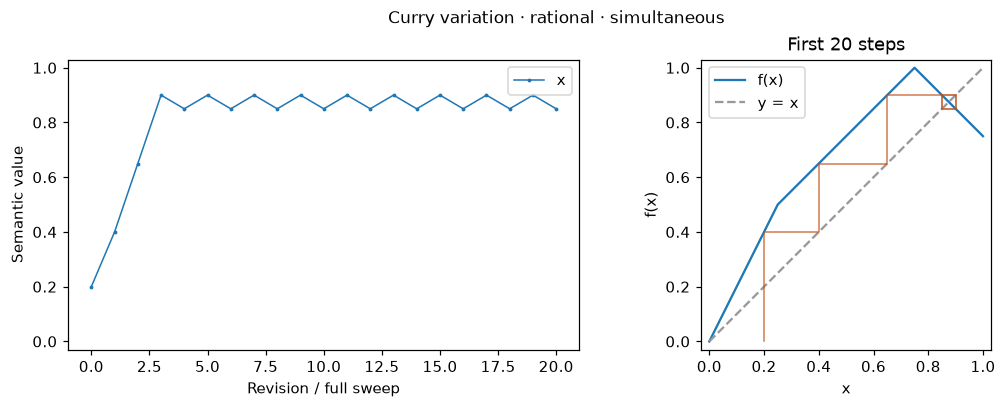

In [10]:
curry = simulate("curry", "1/5", parameters={"p": "3/4"}, steps=20, precision="rational")
print("Interior cycle:", curry.states[-4:])
boundary = simulate("curry", "0.23", parameters={"p": "1"}, steps=4, precision="rational")
print("p=1:", [str(x) for (x,) in boundary.states])
display(plot_trajectory(curry))
plt.close("all")

## 8. Export a reproducible experiment

JSON records the equation, source pages, code hashes, initial inputs, represented
values, parameters, arithmetic, schedule, complete trajectory and diagnostics.
CSV retains fraction strings for exact runs. Use a separate output directory for
each experiment.

In [11]:
a.save(Path("scratch/notebook-tent"))
report = a.report()
print("Saved scratch/notebook-tent/trajectory.json and trajectory.csv")
print(
    {key: report[key] for key in ["model", "precision", "update_schedule", "represented_initial"]}
)

Saved scratch/notebook-tent/trajectory.json and trajectory.csv
{'model': 'chaotic-liar', 'precision': 'rational', 'update_schedule': 'simultaneous', 'represented_initial': ['157/500']}


## 9. Try a change

Run the following cell in a live notebook, choose a map and arithmetic, enter
decimal or fraction strings, then press **Run experiment**. Scalar maps disable
coupled controls. Keep the baseline settings and your changed settings in your notes.
The controls use the same simulator as the tests and CLI.

In [12]:
from paradox_dynamics.interactive import explorer

explorer()

## Discussion

- Which property belongs to the revision equation, and which belongs to its numerical representation?
- Which conclusions change when the update order changes?
- Why is a positive local expansion rate insufficient to classify one orbit?
- What evidence beyond an orbit plot would support a claim about an invariant set?
- What additional argument connects these semantic experiments to the claims in *Ingressing Minds*?

Next: change one initial value, parameter, or schedule; export both runs and state
one observation that survives the change and one that does not.